# Face Detection สำหรับ Lip Reading — YOLOv11n Face + PyTorch CUDA

Notebook นี้แยกออกจาก `phase2_face_detection_tracking.ipynb` เดิมโดยสิ้นเชิง

เป้าหมาย:
- ใช้ **YOLOv11n Face Detection** ที่ train บน WIDER FACE
- ใช้ **PyTorch CUDA** โดยตรง ไม่ใช้ ONNX Runtime
- ดาวน์โหลดโมเดลอัตโนมัติครั้งแรก
- ทดสอบ 1 เฟรมก่อน
- ประมวลผล 100 เฟรม
- บันทึก `detection.csv`
- สร้างภาพ preview เพื่อตรวจว่ากรอบครอบหน้าได้ถูกต้อง

> โมเดล face detector ที่ใช้ใน notebook นี้เป็น community model จาก Hugging Face:
> `AdamCodd/YOLOv11n-face-detection`

## Cell 1 — ตรวจ Environment / GPU

ผลที่ต้องการ:
- `CUDA available: True`
- GPU เป็น NVIDIA GeForce RTX 4050 Laptop GPU หรือ GPU ของเครื่องคุณ

In [2]:
import sys
import torch

print("=" * 70)
print("ENVIRONMENT CHECK")
print("=" * 70)
print("Python :", sys.executable)
print("Torch  :", torch.__version__)
print("CUDA available :", torch.cuda.is_available())
print("CUDA version   :", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU            :", torch.cuda.get_device_name(0))
else:
    raise RuntimeError(
        "CUDA ไม่พร้อมใช้งาน กรุณาเลือก Python/Kernel ที่ติดตั้ง PyTorch CUDA"
    )

ENVIRONMENT CHECK
Python : c:\Users\ASUS FA507NUR\AppData\Local\Programs\Python\Python312\python.exe
Torch  : 2.6.0+cu124
CUDA available : True
CUDA version   : 12.4
GPU            : NVIDIA GeForce RTX 4050 Laptop GPU


## Cell 2 — ติดตั้ง dependency ที่จำเป็น

รัน Cell นี้ครั้งแรกครั้งเดียวก็พอ ถ้าติดตั้งอยู่แล้ว pip จะข้ามให้

In [3]:
import sys
import subprocess

packages = [
    "ultralytics",
    "huggingface_hub",
    "opencv-python",
    "pandas",
    "matplotlib",
]

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-U",
    *packages
])

print("Dependencies ready")

Dependencies ready


## Cell 3 — ตั้งค่า Path ของโปรเจกต์

Notebook นี้ออกแบบให้ใช้กับ:
`D:\Face_detection`

In [4]:
from pathlib import Path

PROJECT_ROOT = Path(r"D:\Face_detection")

MODEL_DIR = PROJECT_ROOT / "models"
RAW_VIDEO_DIR = PROJECT_ROOT / "dataset" / "raw_videos"
OUTPUT_ROOT = PROJECT_ROOT / "dataset" / "yolo_face_detection"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RAW_VIDEO_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("MODEL_DIR    :", MODEL_DIR)
print("RAW_VIDEO_DIR:", RAW_VIDEO_DIR)
print("OUTPUT_ROOT  :", OUTPUT_ROOT)

PROJECT_ROOT : D:\Face_detection
MODEL_DIR    : D:\Face_detection\models
RAW_VIDEO_DIR: D:\Face_detection\dataset\raw_videos
OUTPUT_ROOT  : D:\Face_detection\dataset\yolo_face_detection


## Cell 4 — ดาวน์โหลด Face Detection Model

จะดาวน์โหลด `model.pt` จาก Hugging Face และ copy มาเก็บเป็น:
`D:\Face_detection\models\yolov11n-face.pt`

ครั้งแรกต้องมีอินเทอร์เน็ต

In [5]:
from huggingface_hub import hf_hub_download
import shutil

HF_REPO = "AdamCodd/YOLOv11n-face-detection"
HF_FILENAME = "model.pt"

LOCAL_MODEL_PATH = MODEL_DIR / "yolov11n-face.pt"

if not LOCAL_MODEL_PATH.exists():
    print("กำลังดาวน์โหลด face detector...")

    downloaded_path = hf_hub_download(
        repo_id=HF_REPO,
        filename=HF_FILENAME,
    )

    shutil.copy2(
        downloaded_path,
        LOCAL_MODEL_PATH
    )

    print("ดาวน์โหลดสำเร็จ")
else:
    print("พบโมเดลเดิมแล้ว ไม่ต้องดาวน์โหลดใหม่")

print("Model path :", LOCAL_MODEL_PATH)
print("Model exists:", LOCAL_MODEL_PATH.exists())

c:\Users\ASUS FA507NUR\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


พบโมเดลเดิมแล้ว ไม่ต้องดาวน์โหลดใหม่
Model path : D:\Face_detection\models\yolov11n-face.pt
Model exists: True


## Cell 5 — โหลดโมเดลและตรวจ Class

**สำคัญ:** ต้องได้ class เป็น `face` เท่านั้น

ถ้าเห็น `person`, `car`, `dog` ฯลฯ แปลว่าโหลดผิดโมเดล

In [6]:
from ultralytics import YOLO

face_model = YOLO(str(LOCAL_MODEL_PATH))

print("Model classes:")
print(face_model.names)

if len(face_model.names) != 1:
    raise RuntimeError(
        f"โมเดลนี้มี {len(face_model.names)} classes "
        "ไม่ใช่ face-only detector"
    )

print("Face detector ready")

Model classes:
{0: 'face'}
Face detector ready


## Cell 6 — หาไฟล์วิดีโอใน `dataset/raw_videos`

จะใช้วิดีโอไฟล์แรกเป็นตัวทดสอบก่อน

In [7]:
SUPPORTED_EXTENSIONS = {
    ".mp4", ".webm", ".avi", ".mov",
    ".mkv", ".mpeg", ".mpg"
}

videos = sorted([
    p for p in RAW_VIDEO_DIR.iterdir()
    if p.is_file()
    and p.suffix.lower() in SUPPORTED_EXTENSIONS
])

print("Videos found:", len(videos))

for i, video in enumerate(videos):
    print(f"[{i}] {video.name}")

if not videos:
    raise FileNotFoundError(
        f"ไม่พบวิดีโอใน {RAW_VIDEO_DIR}"
    )

VIDEO_PATH = videos[0]
print("\nUsing:", VIDEO_PATH)

Videos found: 2
[0] video001.webm
[1] video002.webm

Using: D:\Face_detection\dataset\raw_videos\video001.webm


## Cell 7 — อ่าน 1 เฟรมจากวิดีโอ

เราจะทดสอบ detection กับ 1 เฟรมก่อนเสมอ

In [8]:
import cv2

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError(f"เปิดวิดีโอไม่ได้: {VIDEO_PATH}")

ret, frame = cap.read()
cap.release()

if not ret or frame is None:
    raise RuntimeError("อ่านเฟรมแรกไม่ได้")

print("Frame shape:", frame.shape)

Frame shape: (1080, 1920, 3)


## Cell 8 — Detect 1 เฟรมด้วย GPU

ถ้า CUDA พร้อม จะใช้ `device=0`

In [9]:
results = face_model.predict(
    source=frame,
    imgsz=640,
    conf=0.35,
    iou=0.50,
    device=0,
    verbose=False,
)

result = results[0]

print("Faces detected:", len(result.boxes))

for i, box in enumerate(result.boxes):
    xyxy = box.xyxy[0].detach().cpu().numpy()
    conf = float(box.conf[0].detach().cpu())

    print(
        f"Face {i}: "
        f"bbox={xyxy.round(1).tolist()} "
        f"conf={conf:.3f}"
    )

Faces detected: 2
Face 0: bbox=[529.0999755859375, 305.70001220703125, 671.7999877929688, 498.1000061035156] conf=0.833
Face 1: bbox=[1269.5, 276.8999938964844, 1410.4000244140625, 479.0] conf=0.825


## Cell 9 — แสดงกรอบ Face Detection

ตรวจด้วยตาว่า:
- กรอบครอบ **เฉพาะใบหน้า**
- ไม่ครอบทั้งตัว
- ไม่จับวัตถุอื่น

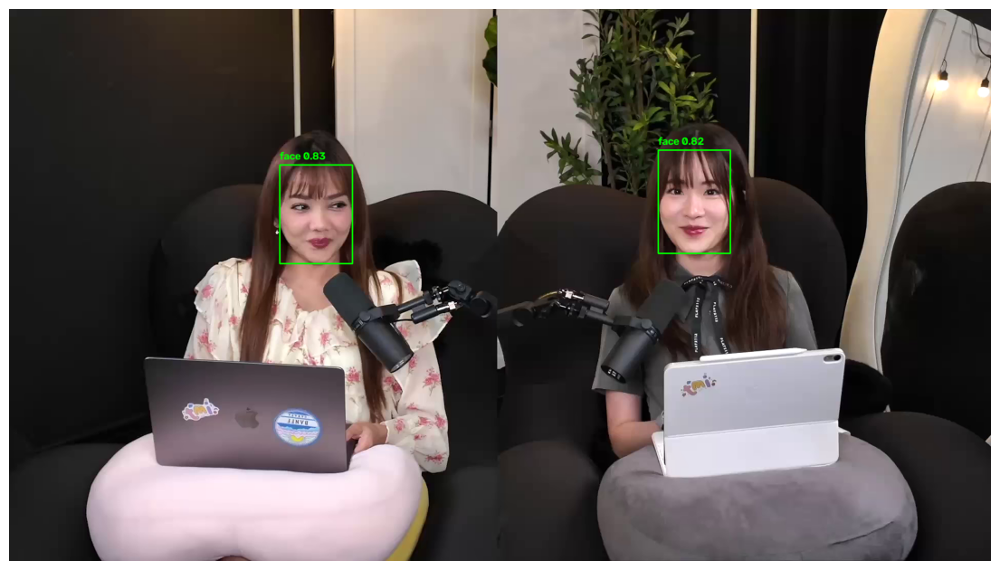

In [10]:
import matplotlib.pyplot as plt

preview = frame.copy()

for box in result.boxes:
    x1, y1, x2, y2 = map(
        int,
        box.xyxy[0].detach().cpu().tolist()
    )

    conf = float(
        box.conf[0].detach().cpu()
    )

    cv2.rectangle(
        preview,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    cv2.putText(
        preview,
        f"face {conf:.2f}",
        (x1, max(25, y1 - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 0),
        2,
        cv2.LINE_AA
    )

preview_rgb = cv2.cvtColor(
    preview,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(14, 8))
plt.imshow(preview_rgb)
plt.axis("off")
plt.show()

## Cell 10 — Simple Face Tracker

ใช้ IoU เพื่อรักษา `track_id` เบื้องต้นระหว่างเฟรม

สำหรับการทดสอบ pipeline ก่อนสร้าง dataset จริง วิธีนี้เพียงพอ
ถ้าภายหลังมีหลายคนและสลับตัวบ่อย เราค่อยเปลี่ยนเป็น ByteTrack

In [11]:
def bbox_iou(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(0.0, ix2 - ix1)
    ih = max(0.0, iy2 - iy1)

    inter = iw * ih

    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)

    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0


class SimpleIoUTracker:
    def __init__(self, iou_threshold=0.30, max_missing=12):
        self.iou_threshold = iou_threshold
        self.max_missing = max_missing
        self.next_track_id = 0
        self.tracks = {}

    def update(self, detections):
        # เพิ่ม missing ของ track เก่าก่อน
        for track in self.tracks.values():
            track["missing"] += 1

        used_tracks = set()
        output = []

        # match detection กับ track ที่ IoU สูงสุด
        for det in detections:
            bbox = det["bbox"]

            best_id = None
            best_iou = 0.0

            for track_id, track in self.tracks.items():
                if track_id in used_tracks:
                    continue

                score = bbox_iou(
                    bbox,
                    track["bbox"]
                )

                if score > best_iou:
                    best_iou = score
                    best_id = track_id

            if (
                best_id is not None
                and best_iou >= self.iou_threshold
            ):
                track_id = best_id
            else:
                track_id = self.next_track_id
                self.next_track_id += 1

            self.tracks[track_id] = {
                "bbox": bbox,
                "missing": 0,
            }

            used_tracks.add(track_id)

            det = dict(det)
            det["track_id"] = track_id
            output.append(det)

        # ลบ track ที่หายไปนาน
        stale = [
            track_id
            for track_id, track in self.tracks.items()
            if track["missing"] > self.max_missing
        ]

        for track_id in stale:
            del self.tracks[track_id]

        return output


print("SimpleIoUTracker ready")

SimpleIoUTracker ready


## Cell 11 — ทดสอบ 100 เฟรม + Export CSV + Preview

เริ่มจาก 100 เฟรมก่อนเท่านั้น

ผลลัพธ์:
- `dataset/yolo_face_detection/<video_id>/detection.csv`
- `dataset/yolo_face_detection/<video_id>/preview/*.jpg`

In [13]:
import cv2
import pandas as pd

# ============================================================
# CONFIG
# ============================================================

MAX_FRAMES = None          # None = รันจนจบวิดีโอ
PREVIEW_EVERY = 1000       # เซฟ preview ทุก 1000 เฟรม
CONF_THRESHOLD = 0.35
IMAGE_SIZE = 640


# ============================================================
# PATH
# ============================================================

video_id = VIDEO_PATH.stem

video_output = OUTPUT_ROOT / video_id
preview_dir = video_output / "preview"

video_output.mkdir(
    parents=True,
    exist_ok=True
)

preview_dir.mkdir(
    parents=True,
    exist_ok=True
)

csv_path = video_output / "detection.csv"


# ============================================================
# OPEN VIDEO
# ============================================================

cap = cv2.VideoCapture(
    str(VIDEO_PATH)
)

if not cap.isOpened():
    raise RuntimeError(
        f"เปิดวิดีโอไม่ได้: {VIDEO_PATH}"
    )

fps = float(
    cap.get(cv2.CAP_PROP_FPS)
)

width = int(
    cap.get(cv2.CAP_PROP_FRAME_WIDTH)
)

height = int(
    cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
)

total_frames = int(
    cap.get(cv2.CAP_PROP_FRAME_COUNT)
)


print("=" * 70)
print("FACE DETECTION — FULL VIDEO")
print("=" * 70)

print("Video       :", VIDEO_PATH.name)
print("FPS         :", fps)
print("Resolution  :", width, "x", height)
print("Total frames:", total_frames)
print("MAX_FRAMES  :", MAX_FRAMES)
print("Preview     :", PREVIEW_EVERY)

print("=" * 70)


# ============================================================
# TRACKER
# ============================================================

tracker = SimpleIoUTracker(
    iou_threshold=0.30,
    max_missing=12,
)


# ============================================================
# VARIABLES
# ============================================================

rows = []

frame_index = 0
processed = 0


# ============================================================
# MAIN LOOP
# ============================================================

while True:

    # --------------------------------------------------------
    # Read frame
    # --------------------------------------------------------

    ret, frame = cap.read()

    if not ret:
        print("\nถึงท้ายวิดีโอแล้ว")
        break


    # --------------------------------------------------------
    # Face Detection
    # --------------------------------------------------------

    pred = face_model.predict(
        source=frame,
        imgsz=IMAGE_SIZE,
        conf=CONF_THRESHOLD,
        iou=0.50,
        device=0,
        verbose=False,
    )[0]


    # --------------------------------------------------------
    # Convert detections
    # --------------------------------------------------------

    detections = []

    for face_index, box in enumerate(
        pred.boxes
    ):

        x1, y1, x2, y2 = (
            box.xyxy[0]
            .detach()
            .cpu()
            .numpy()
            .astype(float)
            .tolist()
        )

        score = float(
            box.conf[0]
            .detach()
            .cpu()
        )

        detections.append({
            "face_index": face_index,
            "bbox": [x1, y1, x2, y2],
            "score": score,
        })


    # --------------------------------------------------------
    # Tracking
    # --------------------------------------------------------

    tracked = tracker.update(
        detections
    )


    # --------------------------------------------------------
    # Timestamp
    # --------------------------------------------------------

    timestamp = (
        frame_index / fps
        if fps > 0
        else 0.0
    )


    # --------------------------------------------------------
    # Preview frame
    # --------------------------------------------------------

    preview_frame = frame.copy()


    # --------------------------------------------------------
    # Store detections
    # --------------------------------------------------------

    for det in tracked:

        x1, y1, x2, y2 = det["bbox"]

        track_id = det["track_id"]

        score = det["score"]


        rows.append({

            "video_id":
                video_id,

            "frame_index":
                frame_index,

            "timestamp_seconds":
                round(timestamp, 6),

            "track_id":
                track_id,

            "face_index":
                det["face_index"],

            "x1":
                round(x1, 3),

            "y1":
                round(y1, 3),

            "x2":
                round(x2, 3),

            "y2":
                round(y2, 3),

            "face_width":
                round(x2 - x1, 3),

            "face_height":
                round(y2 - y1, 3),

            "det_score":
                round(score, 6),

        })


        # ----------------------------------------------------
        # Draw bounding box
        # ----------------------------------------------------

        cv2.rectangle(
            preview_frame,
            (int(x1), int(y1)),
            (int(x2), int(y2)),
            (0, 255, 0),
            2,
        )


        # ----------------------------------------------------
        # Draw Track ID
        # ----------------------------------------------------

        cv2.putText(
            preview_frame,
            f"ID {track_id} {score:.2f}",
            (
                int(x1),
                max(
                    25,
                    int(y1) - 10
                )
            ),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 0),
            2,
            cv2.LINE_AA,
        )


    # --------------------------------------------------------
    # Save Preview
    # --------------------------------------------------------

    if (
        PREVIEW_EVERY > 0
        and
        processed % PREVIEW_EVERY == 0
    ):

        out_path = (
            preview_dir
            / f"frame_{frame_index:08d}.jpg"
        )

        cv2.imwrite(
            str(out_path),
            preview_frame
        )


    # --------------------------------------------------------
    # Update counters
    # --------------------------------------------------------

    processed += 1
    frame_index += 1


    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if processed % 100 == 0:

        percent = (
            processed
            / total_frames
            * 100
            if total_frames > 0
            else 0
        )

        print(
            f"Processed "
            f"{processed:,} / "
            f"{total_frames:,} frames "
            f"({percent:.2f}%) | "
            f"detections={len(rows):,}"
        )


    # --------------------------------------------------------
    # Optional MAX_FRAMES stop
    # --------------------------------------------------------

    if (
        MAX_FRAMES is not None
        and
        processed >= MAX_FRAMES
    ):
        print(
            f"\nReached MAX_FRAMES = "
            f"{MAX_FRAMES}"
        )

        break


# ============================================================
# CLOSE VIDEO
# ============================================================

cap.release()


# ============================================================
# SAVE CSV
# ============================================================

df = pd.DataFrame(
    rows
)

df.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)

print(
    "Processed frames:",
    f"{processed:,}"
)

print(
    "Detections      :",
    f"{len(df):,}"
)

print(
    "CSV             :",
    csv_path
)

print(
    "Preview         :",
    preview_dir
)

print("=" * 70)

display(
    df.head(10)
)

FACE DETECTION — FULL VIDEO
Video       : video001.webm
FPS         : 29.97002997002997
Resolution  : 1920 x 1080
Total frames: 178335
MAX_FRAMES  : None
Preview     : 1000
Processed 100 / 178,335 frames (0.06%) | detections=200
Processed 200 / 178,335 frames (0.11%) | detections=400
Processed 300 / 178,335 frames (0.17%) | detections=600
Processed 400 / 178,335 frames (0.22%) | detections=800
Processed 500 / 178,335 frames (0.28%) | detections=1,000
Processed 600 / 178,335 frames (0.34%) | detections=1,200
Processed 700 / 178,335 frames (0.39%) | detections=1,345
Processed 800 / 178,335 frames (0.45%) | detections=1,519
Processed 900 / 178,335 frames (0.50%) | detections=1,719
Processed 1,000 / 178,335 frames (0.56%) | detections=1,919
Processed 1,100 / 178,335 frames (0.62%) | detections=2,119
Processed 1,200 / 178,335 frames (0.67%) | detections=2,319
Processed 1,300 / 178,335 frames (0.73%) | detections=2,519
Processed 1,400 / 178,335 frames (0.79%) | detections=2,684
Processed 1,5

,video_id,frame_index,timestamp_seconds,track_id,face_index,x1,y1,x2,y2,face_width,face_height,det_score
0,video001,0,0.000000,0,0,529.128,305.736,671.765,498.087,142.637,192.351,0.833094
1,video001,0,0.000000,1,1,1269.474,276.933,1410.382,478.952,140.908,202.019,0.824791
2,video001,1,0.033367,0,0,529.254,305.274,671.930,497.819,142.676,192.545,0.834487
3,video001,1,0.033367,1,1,1269.540,275.139,1410.256,479.024,140.716,203.885,0.826267
4,video001,2,0.066733,0,0,528.629,305.161,671.965,497.940,143.336,192.779,0.834542
5,video001,2,0.066733,1,1,1270.542,273.439,1410.241,480.312,139.699,206.874,0.825334
6,video001,3,0.100100,0,0,528.470,305.528,671.986,497.878,143.516,192.349,0.835783
7,video001,3,0.100100,1,1,1270.974,271.983,1411.374,481.624,140.400,209.641,0.826308
8,video001,4,0.133467,0,0,528.339,304.176,671.636,497.745,143.297,193.569,0.832522
9,video001,4,0.133467,1,1,1271.542,268.377,1411.490,481.465,139.948,213.088,0.826028


In [16]:
print("Processed frames:", processed)
print("Detection rows:", len(df))
print("Max frame:", df["frame_index"].max())
print("Track IDs:", sorted(df["track_id"].unique()))
print("CSV:", csv_path)

Processed frames: 178334
Detection rows: 256620
Max frame: 178333
Track IDs: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64

In [17]:
import pandas as pd

csv_path = r"D:\Face_detection\dataset\yolo_face_detection\video001\detection.csv"

df = pd.read_csv(csv_path)

track_stats = (
    df.groupby("track_id")
      .agg(
          detections=("frame_index", "count"),
          first_frame=("frame_index", "min"),
          last_frame=("frame_index", "max"),
      )
      .sort_values("detections", ascending=False)
)

track_stats["duration_frames"] = (
    track_stats["last_frame"] -
    track_stats["first_frame"] + 1
)

display(track_stats.head(30))

,detections,first_frame,last_frame,duration_frames
track_id,,,,
166,7507,129166,136672,7507
167,7507,129166,136672,7507
30,6312,6716,13027,6312
149,6260,113571,119830,6260
66,6183,38727,44909,6183
67,6183,38727,44909,6183
97,4850,61794,66643,4850
186,4617,145898,150514,4617
107,4578,72804,77381,4578


In [18]:
print("จำนวน Track ทั้งหมด:", df["track_id"].nunique())

print("\n10 Track ที่มี detection เยอะที่สุด:")
print(
    df["track_id"]
      .value_counts()
      .head(10)
)

จำนวน Track ทั้งหมด: 256

10 Track ที่มี detection เยอะที่สุด:
track_id
166    7507
167    7507
30     6312
149    6260
66     6183
67     6183
97     4850
186    4617
107    4578
108    4578
Name: count, dtype: int64


In [19]:
import pandas as pd

df = pd.read_csv(
    r"D:\Face_detection\dataset\yolo_face_detection\video001\detection.csv"
)

track_stats = (
    df.groupby("track_id")
    .agg(
        detections=("frame_index", "count"),
        first_frame=("frame_index", "min"),
        last_frame=("frame_index", "max"),

        mean_x1=("x1", "mean"),
        mean_y1=("y1", "mean"),
        mean_x2=("x2", "mean"),
        mean_y2=("y2", "mean"),

        mean_width=("face_width", "mean"),
        mean_height=("face_height", "mean"),

        mean_conf=("det_score", "mean"),
    )
    .reset_index()
)

track_stats["span"] = (
    track_stats["last_frame"]
    - track_stats["first_frame"]
    + 1
)

track_stats["coverage"] = (
    track_stats["detections"]
    / track_stats["span"]
)

track_stats = track_stats.sort_values(
    "detections",
    ascending=False
)

display(track_stats.head(30))

,track_id,detections,first_frame,last_frame,mean_x1,mean_y1,mean_x2,mean_y2,mean_width,mean_height,mean_conf,span,coverage
166,166,7507,129166,136672,480.865420,310.967843,619.837693,506.381172,138.972278,195.413326,0.826566,7507,1.0
167,167,7507,129166,136672,1303.350177,305.348618,1442.362292,500.349906,139.012109,195.001282,0.814418,7507,1.0
30,30,6312,6716,13027,841.375727,300.534614,980.366508,496.753490,138.990782,196.218879,0.826522,6312,1.0
149,149,6260,113571,119830,915.800665,314.962138,1051.055687,517.752747,135.255011,202.790604,0.815935,6260,1.0
66,66,6183,38727,44909,1305.113476,291.819384,1443.996254,489.918934,138.882779,198.099544,0.815682,6183,1.0
67,67,6183,38727,44909,512.013214,314.697549,653.424603,509.920127,141.411393,195.222575,0.827045,6183,1.0
97,97,4850,61794,66643,916.183348,300.406515,1053.144696,503.543036,136.961352,203.136529,0.818530,4850,1.0
186,186,4617,145898,150514,911.973088,309.102768,1045.843711,509.825119,133.870627,200.722345,0.819730,4617,1.0
107,107,4578,72804,77381,475.162346,307.588296,618.897273,504.289194,143.734930,196.700898,0.829947,4578,1.0
108,108,4578,72804,77381,1303.187297,306.253802,1443.385708,500.187554,140.198400,193.933746,0.821302,4578,1.0


In [20]:
top_ids = track_stats.head(20)["track_id"].tolist()

for tid in top_ids:
    row = track_stats[
        track_stats["track_id"] == tid
    ].iloc[0]

    print(
        f"Track {tid:3d} | "
        f"frames {int(row.first_frame):6d}"
        f" -> {int(row.last_frame):6d} | "
        f"detections={int(row.detections):5d} | "
        f"coverage={row.coverage:.2%} | "
        f"position=({row.mean_x1:.0f}, {row.mean_y1:.0f})"
    )

Track 166 | frames 129166 -> 136672 | detections= 7507 | coverage=100.00% | position=(481, 311)
Track 167 | frames 129166 -> 136672 | detections= 7507 | coverage=100.00% | position=(1303, 305)
Track  30 | frames   6716 ->  13027 | detections= 6312 | coverage=100.00% | position=(841, 301)
Track 149 | frames 113571 -> 119830 | detections= 6260 | coverage=100.00% | position=(916, 315)
Track  66 | frames  38727 ->  44909 | detections= 6183 | coverage=100.00% | position=(1305, 292)
Track  67 | frames  38727 ->  44909 | detections= 6183 | coverage=100.00% | position=(512, 315)
Track  97 | frames  61794 ->  66643 | detections= 4850 | coverage=100.00% | position=(916, 300)
Track 186 | frames 145898 -> 150514 | detections= 4617 | coverage=100.00% | position=(912, 309)
Track 107 | frames  72804 ->  77381 | detections= 4578 | coverage=100.00% | position=(475, 308)
Track 108 | frames  72804 ->  77381 | detections= 4578 | coverage=100.00% | position=(1303, 306)
Track 134 | frames  97430 -> 101972 |

## Cell 12 — สรุปจำนวนใบหน้าต่อ Track

ใช้ดูว่าระบบ tracking มีการแตก ID มากเกินไปหรือไม่

In [14]:
if len(df) == 0:
    print("ยังไม่มี detection")
else:
    summary = (
        df.groupby("track_id")
          .agg(
              detections=("frame_index", "count"),
              first_frame=("frame_index", "min"),
              last_frame=("frame_index", "max"),
              mean_confidence=("det_score", "mean"),
          )
          .sort_values(
              "detections",
              ascending=False
          )
    )

    display(summary)

,detections,first_frame,last_frame,mean_confidence
track_id,,,,
166,7507,129166,136672,0.826566
167,7507,129166,136672,0.814418
30,6312,6716,13027,0.826522
149,6260,113571,119830,0.815935
66,6183,38727,44909,0.815682
...,...,...,...,...
18,22,3738,3759,0.385966
183,13,145442,145454,0.595410
158,11,123177,123197,0.434329


## Cell 13 — ดูภาพ Preview ที่สร้างล่าสุด

หากกรอบเขียวครอบหน้าได้ถูกต้องต่อเนื่อง เราค่อยเพิ่มจาก 100 เฟรมเป็นทั้งวิดีโอ

Preview images: 188
frame_00000000.jpg


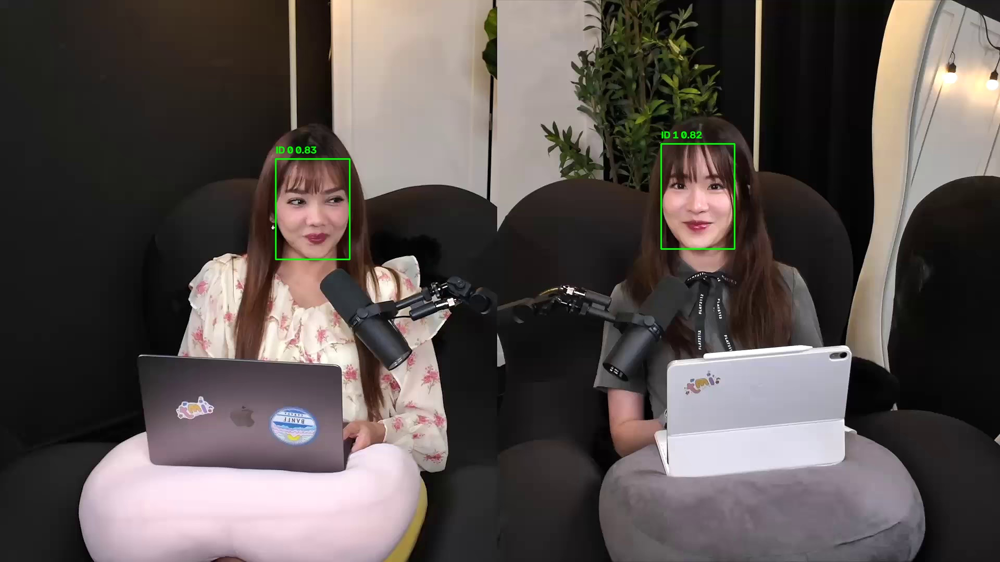

frame_00000010.jpg


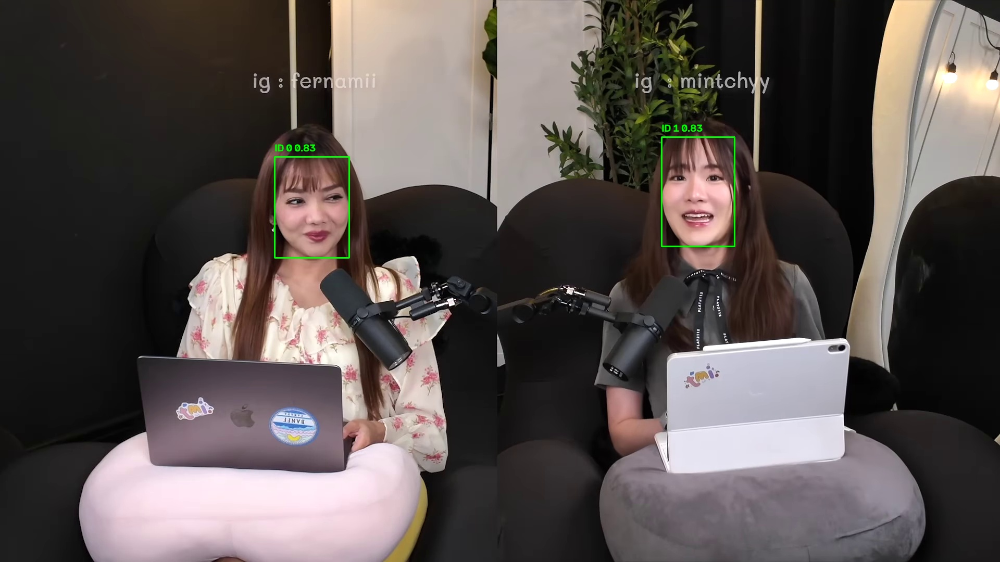

frame_00000020.jpg


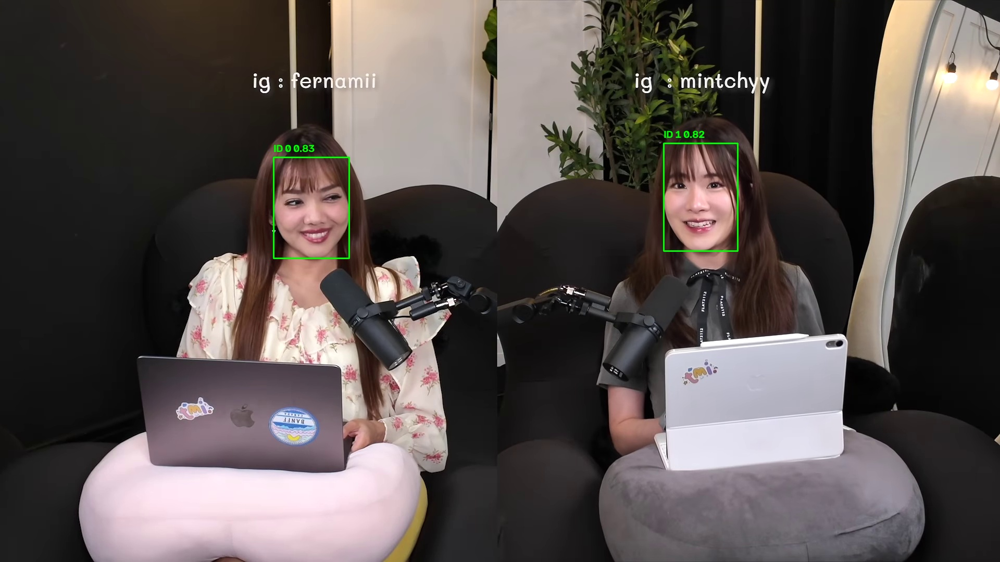

frame_00000030.jpg


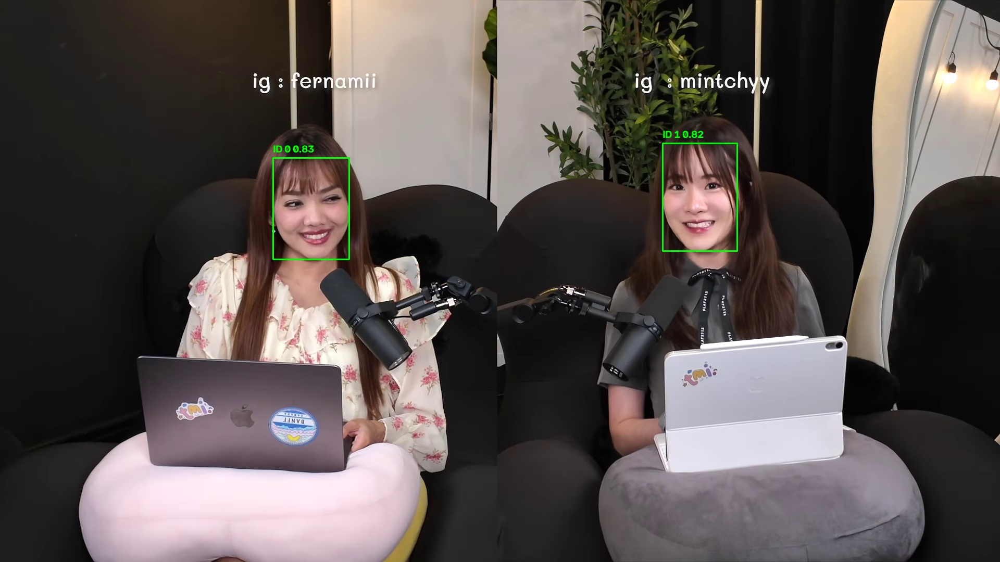

frame_00000040.jpg


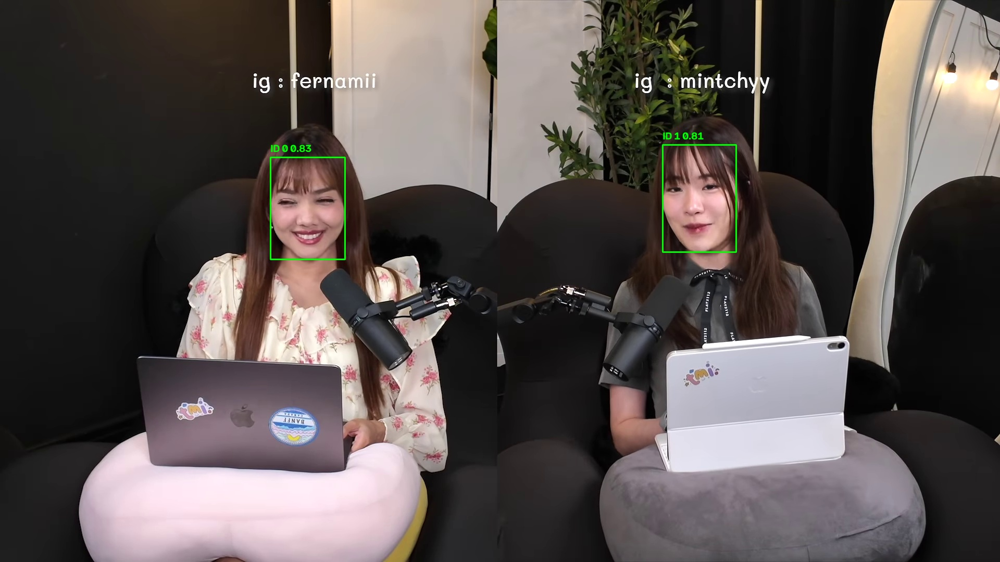

frame_00000050.jpg


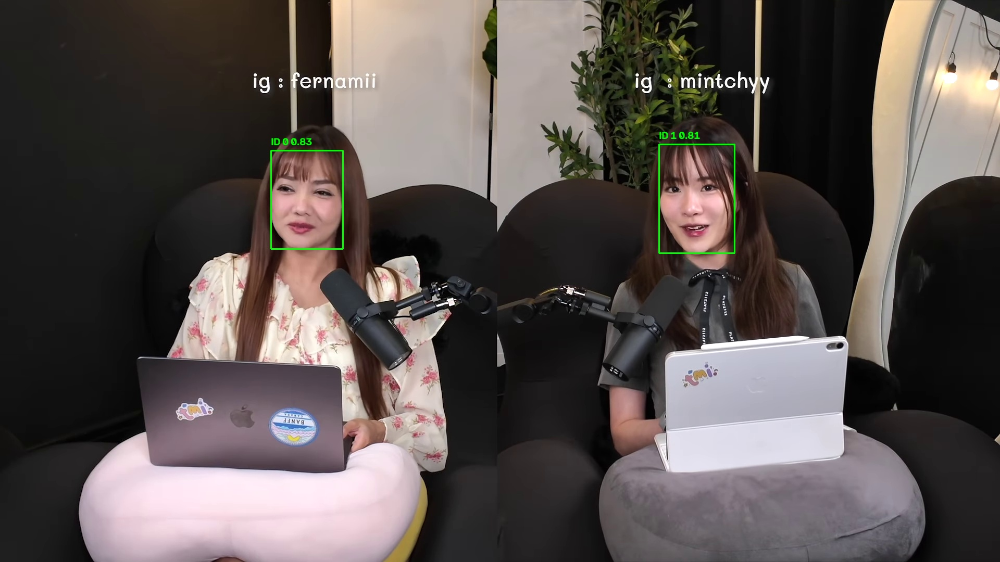

frame_00000060.jpg


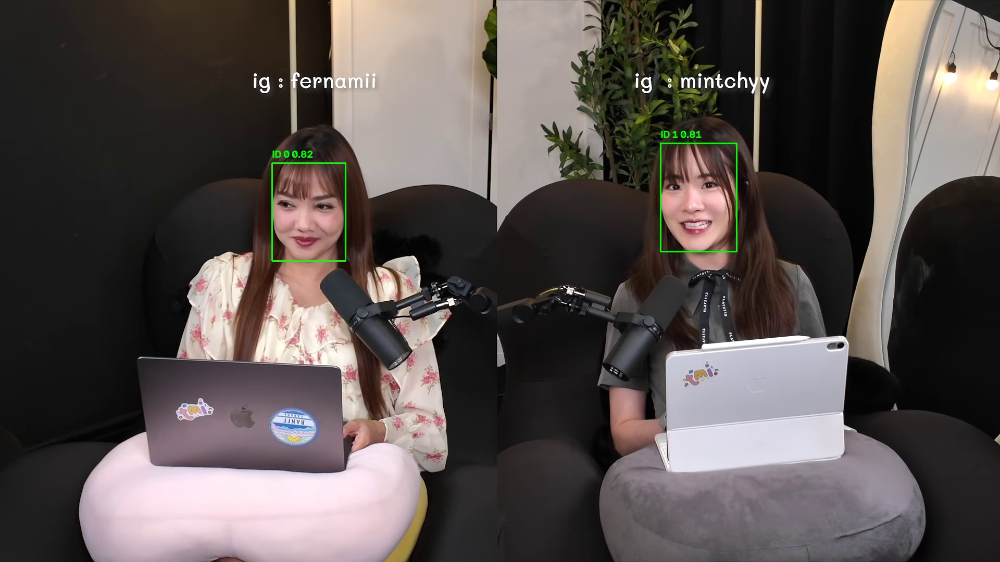

frame_00000070.jpg


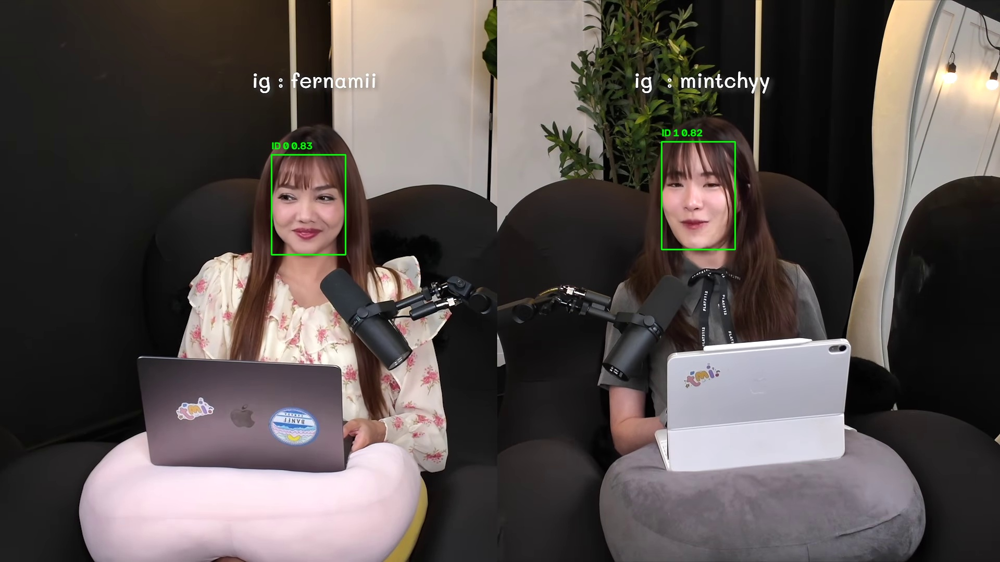

frame_00000080.jpg


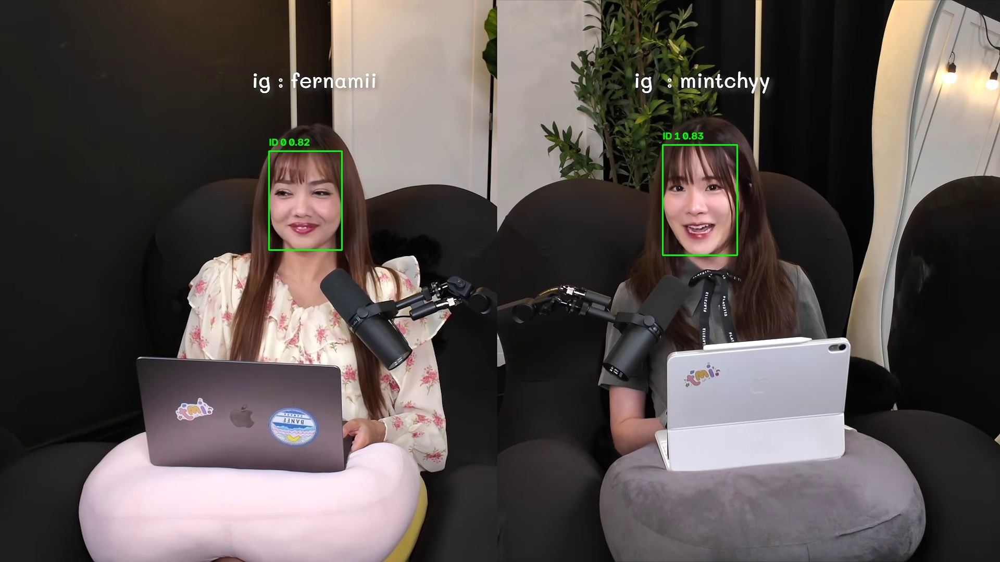

frame_00000090.jpg


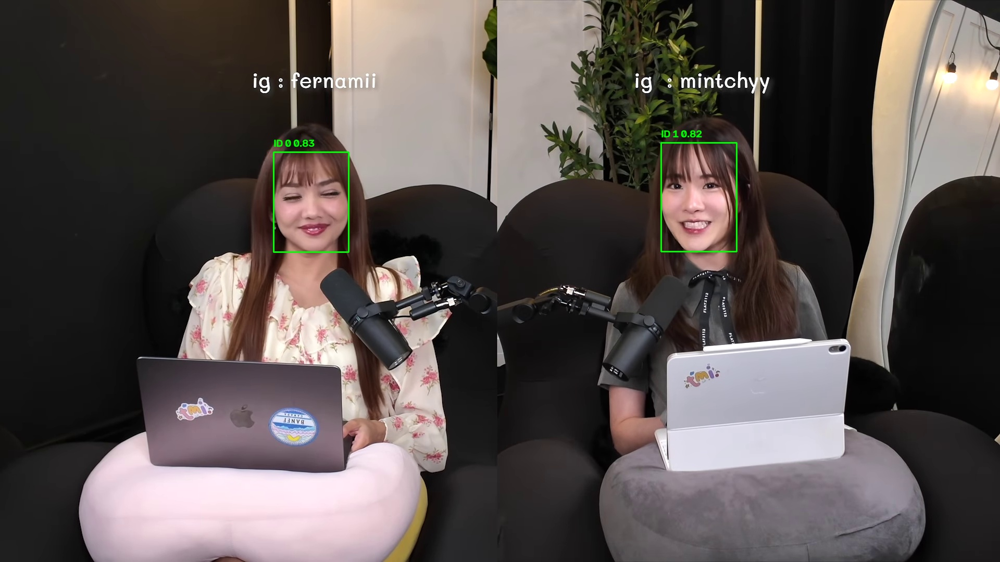

In [15]:
from IPython.display import display
from PIL import Image

preview_files = sorted(
    preview_dir.glob("*.jpg")
)

print("Preview images:", len(preview_files))

for image_path in preview_files[:10]:
    print(image_path.name)
    display(
        Image.open(image_path)
    )

# ขั้นต่อไปหลัง 100 เฟรมผ่าน

อย่าเพิ่งรันทั้งคลิปจนกว่าจะตรวจ preview แล้ว

เมื่อ Face Detection ผ่าน เราจะทำ Notebook ใหม่อีกตัวสำหรับ:

1. เลือก speaker/track ที่ต้องการ
2. Face alignment
3. Facial landmarks
4. Crop Mouth ROI
5. Normalize เป็น 96×96
6. Quality filtering
7. สร้าง temporal lip sequence
8. เชื่อมกับ transcript ภาษาไทย